# Building a MovieLens Recommender System


Want to know how Spotify, Amazon, and Netflix generate recommendations for their users? In this lab, we will explore collaborative filtering.

## Objective
We will build our own recommendation system using the Movie dataset in Python to recommend movies to its users based on their movie ratings.
### Lab Outline

This lab includes :

1. Import dependencies
1. Load the movies data
1. Exploratory data analysis : Most Frequently Rated Items , Lowest vs Highest
   rated Item
   * Mean
   * Bayesian Average
1. Data Preprocessing:
   * Convert to user-item utility matrix and sparsity matrix
1. Collaborative filtering (item-to-item) using k-Nearest Neighbors
1. Dimensionality reduction with matrix factorization (Optional)



### Step 1: Import Dependencies

We are using [pandas.DataFrame](http://pandas.pydata.org/pandas-docs/version/0.19/generated/pandas.DataFrame.html) to represent our data. We will visualize our data with [matplotlib](https://matplotlib.org/) and [seaborn](https://seaborn.pydata.org/).

**What is a DataFrame?**

- a two-dimensional Pandas data structure
- columns represent features, rows represent items
- analogous to an Excel spreadsheet or SQL table

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Data

Let's download a small version of the MovieLens dataset. You can download the data (https://grouplens.org/datasets/movielens/).




We're working with data and will need to add the following files to your google drive:

- ratings.csv
- movies.csv



In [ ]:
# First, you'll need to mount your Google Drive to access files stored there. Upload both movies.csv and ratings.csv into your google drive folder
from google.colab import drive
drive.mount('/content/drive')

# Define the file path
file_path_movie = '/content/drive/MyDrive/Colab Notebooks/movies.csv'
# Define the file path
file_path_rating = '/content/drive/MyDrive/Colab Notebooks/ratings.csv'

movies = pd.read_csv(file_path_movie)
ratings = pd.read_csv(file_path_rating)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Step 3: Exploratory Data Analysis

Summary of the dataset by reporting

**len(ratings)**
- Calculates the total number of ratings in the dataset.
n_movies = ratings['movieId'].nunique()

**ratings['movieId'].nunique()**
- finds the number of unique movies in the dataset.

**nunique()**
- counts the number of distinct movie IDs, which tells us how many different movies have been rated

**ratings['userId'].nunique()**
- calculates the number of unique users in the dataset.

In [ ]:
n_ratings = len(ratings)
n_movies = ratings['movieId'].nunique()
n_users = ratings['userId'].nunique()

print(f"Number of movies ratings: {n_ratings}")
print(f"Number of unique movieid's: {n_movies}")
print(f"Number of unique users: {n_users}")
print(f"Average number of ratings per user: {round(n_ratings/n_users, 2)}")
print(f"Average number of ratings per movie: {round(n_ratings/n_movies, 2)}")

Number of ratings: 100836
Number of unique movieId's: 9724
Number of unique users: 610
Average number of ratings per user: 165.3
Average number of ratings per movie: 10.37


### Most frequently rated movies

`Forrest Gump`, `Shawshank Redemption`, and `Pulp Fiction` have the most ratings.

In [68]:
movie_ratings = ratings.merge(movies, on='movieId')
movie_ratings['title'].value_counts()[0:10]


,count
title,
Forrest Gump (1994),329
"Shawshank Redemption, The (1994)",317
Pulp Fiction (1994),307
"Silence of the Lambs, The (1991)",279
"Matrix, The (1999)",278
Star Wars: Episode IV - A New Hope (1977),251
Jurassic Park (1993),238
Braveheart (1995),237
Terminator 2: Judgment Day (1991),224


### Lowest vs Highest-rated movies




`Gypsy` has the lowest average rating.


*   idxmin(): Finds the movie ID with the lowest average rating.
*   groupby('movieId')['rating'].mean(): Groups ratings by movieId and
     calculates the average rating for each movie.


In [70]:
mean_ratings = ratings.groupby('movieId')[['rating']].mean()
lowest_rated = mean_ratings['rating'].idxmin()

# find movie Id with lowest average rating
movies[movies['movieId']==lowest_rated]

# retrieve ratings of the Lowest Rated Movie
ratings[ratings['movieId']==lowest_rated]


,userId,movieId,rating,timestamp
13633,89,3604,0.5,1520408880


`Lamerica` has the highest rating


*   `Lamerica` may be the "highest" rated movie, but it only has 2 ratings.
*   A better approach for evaluating movie popularity is to do look at the [Bayesian average]https://en.wikipedia.org/wiki/Bayesian_average



In [71]:
highest_rated = mean_ratings['rating'].idxmax()
movies[movies['movieId'] == highest_rated]

,movieId,title,genres
48,53,Lamerica (1994),Adventure|Drama


In [ ]:
# retrieve ratings of the highestRated Movie
ratings[ratings['movieId']==highest_rated]

,userId,movieId,rating,timestamp
13368,85,53,5.0,889468268
96115,603,53,5.0,963180003


# Bayesian Average

Bayesian average adjusts ratings using prior information, smoothing results to account for variability and rating sparsity in datasets.

**Bayesian Average** is defined as:

$r_{i} = \frac{C \times m + \Sigma{\text{reviews}}}{C+N}$

where
- $C$ represents our confidence,
- $m$ represents our prior, and
- $N$ is the total number of reviews for movie $i$.
- In this case, our prior $m$ will be the average mean rating across all movies.

By defintion, C represents "the typical data set size". Let's make $C$ be the average number of ratings for a given movie.

(https://en.wikipedia.org/wiki/Bayesian_average)

In [73]:
# Group Ratings by Movie and Compute Statistics:count and mean
movie_stats = ratings.groupby('movieId')['rating'].agg(['count', 'mean'])
movie_stats.head()

,count,mean
movieId,,
1,215,3.920930
2,110,3.431818
3,52,3.259615
4,7,2.357143
5,49,3.071429


In [76]:
# Average number of ratings for a given movie
C = movie_stats['count'].mean()
# Average rating for a given movie
m = movie_stats['mean'].mean()

print(f"Average number of ratings for a given movie: {C:.2f}")
print(f"Average rating for a given movie: {m:.2f}")


# Python function: bayesian_avg(ratings)
# Description: computes a smoothed average rating using a Bayesian approach, combining prior information with observed ratings to handle rating sparsity.
# Arguments: C is the mean count of ratings. m is mean rating
def bayesian_avg(ratings):
    bayesian_avg = (C*m+ratings.sum())/(C+ratings.count())
    return round(bayesian_avg, 3)

Average number of ratings for a given movie: 10.37
Average rating for a given movie: 3.26


Let's test our `bayesian_avg` function out on `Lamerica` - the "highest" rated movie, but it only has 2 ratings.
- `Lamerica`'s **average Bayesian rating** is 3.5.





In [77]:
lamerica = pd.Series([5, 5])
bayesian_avg(lamerica)

3.543

Let's now apply `bayesian_avg` to  **all movies** in our dataset.

- ratings.groupby('movieId'): Groups the ratings by movieId.
- ['rating'].agg(lambda x: bayesian_avg(x, C, m)): Applies the bayesian_avg function to each group of ratings,
- .reset_index(): Converts the resulting Series into a DataFrame and resets the index, making movieId a column.

In [84]:
# Groups the ratings by movieId.
# Applies the bayesian_avg function to each group of ratings
bayesian_avg_ratings = ratings.groupby('movieId')['rating'].agg(bayesian_avg).reset_index()

# renames columns
bayesian_avg_ratings.columns = ['movieId', 'bayesian_avg']
movie_stats = movie_stats.merge(bayesian_avg_ratings, on='movieId')

In [86]:
# Adds movie titles to the movie_stats DataFrame
movie_stats = movie_stats.merge(movies[['movieId', 'title']])

# orders movies by their Bayesian average rating from highest to lowest.
movie_stats.sort_values('bayesian_avg', ascending=False).head()

,movieId,count,mean,bayesian_avg_x,bayesian_avg_y,title,bayesian_avg
277,318,317,4.429022,4.392,4.392,"Shawshank Redemption, The (1994)",4.392
659,858,192,4.289062,4.236,4.236,"Godfather, The (1972)",4.236
2224,2959,218,4.272936,4.227,4.227,Fight Club (1999),4.227
224,260,251,4.231076,4.193,4.193,Star Wars: Episode IV - A New Hope (1977),4.193
46,50,204,4.237745,4.191,4.191,"Usual Suspects, The (1995)",4.191


**Conclusions:**
- Using the **Bayesian average**, we see that `Shawshank Redemption`, `The Godfather`, and `The Usual Suspects` are the most highly rated movies.
- This result makes much more sense since these movies are critically acclaimed films.

In [87]:
# orders movies by their Bayesian average rating from lowest to highest
movie_stats.sort_values('bayesian_avg', ascending=True).head()

,movieId,count,mean,bayesian_avg_x,bayesian_avg_y,title,bayesian_avg
1172,1556,19,1.605263,2.190,2.190,Speed 2: Cruise Control (1997),2.190
2679,3593,19,1.657895,2.224,2.224,Battlefield Earth (2000),2.224
1372,1882,33,1.954545,2.267,2.267,Godzilla (1998),2.267
1144,1499,27,1.925926,2.297,2.297,Anaconda (1997),2.297
1988,2643,16,1.687500,2.307,2.307,Superman IV: The Quest for Peace (1987),2.307


**Further conclusion**
- With Bayesian averaging, it looks like `Speed 2: Cruise Control`, `Battlefield
Earth`, and `Godzilla` are the worst rated movies. `Gypsy` isn't so bad after all.

### Step 4: Data Pre-processing

We are going to use a technique called **collaborative filtering** to generate recommendations for users. This technique is based on the premise that similar people like similar things.

The first step is to transform our data into a **user-item matrix**, also known as a "utility" matrix.

**User-item matrix**
- In this matrix, rows represent users and columns represent movies.
- The beauty of collaborative filtering is that it doesn't require any information about the users or the movies user to generate recommendations.

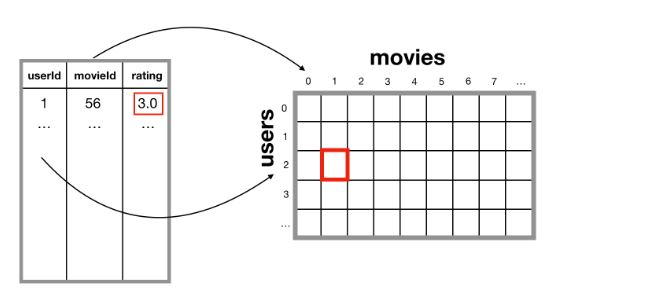




The `create_X()` function outputs a sparse matrix $X$ with four mapper dictionaries:

- **user_mapper**: maps user id to user index
- **movie_mapper**: maps movie id to movie index
- **user_inv_mapper**: maps user index to user id
- **movie_inv_mapper**: maps movie index to movie id

We need these dictionaries because they map which row/column of the utility matrix corresponds to which user/movie id.

Our $X$ (user-item) matrix is a [scipy.sparse.csr_matrix](https://docs.scipy.org/doc/scipy-0.14.0/reference/generated/scipy.sparse.csr_matrix.html) which stores the data sparsely.

In [96]:
from scipy.sparse import csr_matrix

def create_X(df):
    """
    Generates a sparse matrix from ratings dataframe.

    Args:
        df: pandas dataframe containing 3 columns (userId, movieId, rating)

    Returns:
        X: sparse matrix
        user_mapper: dict that maps user id's to user indices
        user_inv_mapper: dict that maps user indices to user id's
        movie_mapper: dict that maps movie id's to movie indices
        movie_inv_mapper: dict that maps movie indices to movie id's
    """
    M = df['userId'].nunique()
    N = df['movieId'].nunique()

    user_mapper = dict(zip(np.unique(df["userId"]), list(range(M))))
    movie_mapper = dict(zip(np.unique(df["movieId"]), list(range(N))))

    user_inv_mapper = dict(zip(list(range(M)), np.unique(df["userId"])))
    movie_inv_mapper = dict(zip(list(range(N)), np.unique(df["movieId"])))

    user_index = [user_mapper[i] for i in df['userId']]
    item_index = [movie_mapper[i] for i in df['movieId']]

    X = csr_matrix((df["rating"], (user_index,item_index)), shape=(M,N))

    return X, user_mapper, movie_mapper, user_inv_mapper, movie_inv_mapper

X, user_mapper, movie_mapper, user_inv_mapper, movie_inv_mapper = create_X(ratings)

In [97]:
X.shape

(610, 9724)

Our `X` matrix contains 610 users and 9724 movies.

### Evaluating sparsity

Here, we calculate sparsity by dividing the number of stored elements by total number of elements. The number of stored (non-empty) elements in our matrix ([nnz](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.csr_matrix.nnz.html)) is equivalent to the number of ratings in our dataset.
- Matrix sparsity is a measure of how many elements in the matrix are zero.
- the sparsity of the matrix X in percentage terms
- **`csr_matrix.nnz`** counts the stored values in our sparse matrix. The rest of our cells are empty.

In [98]:
n_total = X.shape[0]*X.shape[1]
n_ratings = X.nnz
sparsity = n_ratings/n_total
print(f"Matrix sparsity: {round(sparsity*100,2)}%")

Matrix sparsity: 1.7%




The **cold start problem** is when there are new users and movies in our matrix that do not have any ratings.
- In our Movie dataset, all users and movies have at least one rating but in general, it's useful to check which users and movies have **few interactions**.

In [103]:
n_ratings_per_user = X.getnnz(axis=1)
len(n_ratings_per_user)



610

In [104]:
# most active user rated movies count
print(f"Most active user rated {n_ratings_per_user.max()} movies.")
# least active user rated movies count
print(f"Least active user rated {n_ratings_per_user.min()} movies.")

Most active user rated 2698 movies.
Least active user rated 20 movies.


In [105]:
n_ratings_per_movie = X.getnnz(axis=0)
len(n_ratings_per_movie)

9724

In [ ]:
print(f"Most rated movie has {n_ratings_per_movie.max()} ratings.")
print(f"Least rated movie has {n_ratings_per_movie.min()} ratings.")

Most rated movie has 329 ratings.
Least rated movie has 1 ratings.


<ipython-input-107-ab04a9cd3d59>:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(n_ratings_per_user, shade=True)
<ipython-input-107-ab04a9cd3d59>:11: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(n_ratings_per_movie, shade=True)


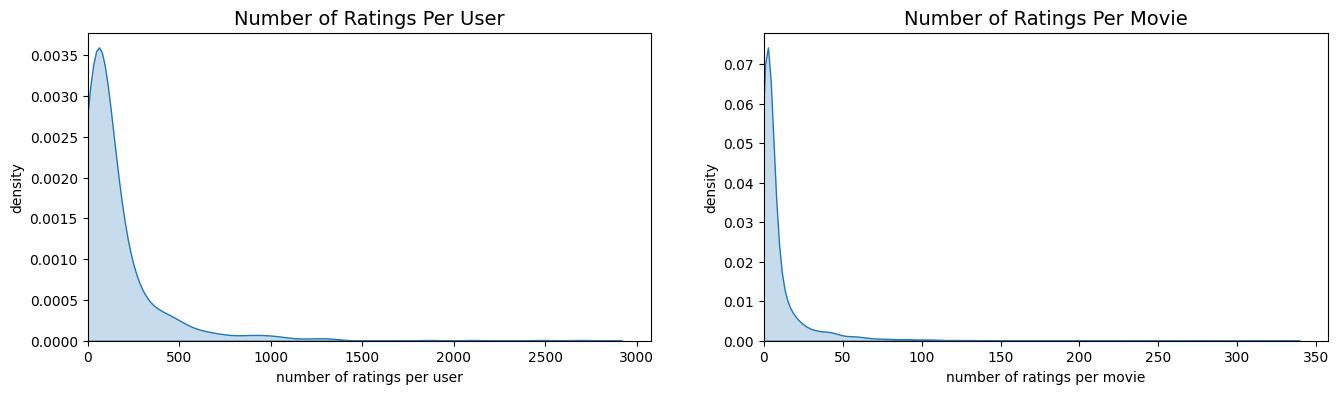

In [107]:
plt.figure(figsize=(16,4))
plt.subplot(1,2,1)
sns.kdeplot(n_ratings_per_user, shade=True)
plt.xlim(0)

# Ratings across users
plt.title("Number of Ratings Per User", fontsize=14)
plt.xlabel("number of ratings per user")
plt.ylabel("density")
plt.subplot(1,2,2)
sns.kdeplot(n_ratings_per_movie, shade=True)
plt.xlim(0)
# Ratings across items
plt.title("Number of Ratings Per Movie", fontsize=14)
plt.xlabel("number of ratings per movie")
plt.ylabel("density")
plt.show()

### Step 5: Item-item Recommendations with k-Nearest Neighbors

We are going to find the $k$ movies that have the most similar user engagement vectors for movie $i$.

**`find_similar_movies()`**
-  aims to find the k nearest neighbors (similar movies) to a given movie ID using a specified distance metric.
- `find_similar_movies()` takes in a `movieId` and `X` matrix, and outputs a list of $k$ movies that are similar to the `movieId` of interest.

In [109]:
from sklearn.neighbors import NearestNeighbors

def find_similar_movies(movie_id, X, movie_mapper, movie_inv_mapper, k, metric='cosine'):
    """
    Finds k-nearest neighbours for a given movie id.

    Args:
        movie_id: id of the movie of interest
        X: user-item utility matrix
        k: number of similar movies to retrieve
        metric: distance metric for kNN calculations

    Output: returns list of k similar movie ID's
    """
    X = X.T
    neighbour_ids = []

    movie_ind = movie_mapper[movie_id]
    movie_vec = X[movie_ind]
    if isinstance(movie_vec, (np.ndarray)):
        movie_vec = movie_vec.reshape(1,-1)
    # use k+1 since kNN output includes the movieId of interest
    kNN = NearestNeighbors(n_neighbors=k+1, algorithm="brute", metric=metric)
    kNN.fit(X)
    neighbour = kNN.kneighbors(movie_vec, return_distance=False)
    for i in range(0,k):
        n = neighbour.item(i)
        neighbour_ids.append(movie_inv_mapper[n])
    neighbour_ids.pop(0)
    return neighbour_ids



- `find_similar_movies()` returns a list of `movieId`'s that are most similar to your movie of interest.

In [110]:
# To find similar movies to the movie with ID 1:
similar_movies = find_similar_movies(1, X, movie_mapper, movie_inv_mapper, k=10)
similar_movies

[3114, 480, 780, 260, 356, 364, 1210, 648, 1265]



-Let's convert these id's to titles so that we can interpret our results.
-To make things easier, we will create a dictionary that maps `movieId` to `title`.

In [111]:
#  create a dictionary that maps movie IDs to titles:
movie_titles = dict(zip(movies['movieId'], movies['title']))

movie_id = 1

# find_similar_movies function to get similar movies for a specific movie ID using k-nearest neighbours
similar_movies = find_similar_movies(movie_id, X, movie_mapper, movie_inv_mapper, metric='cosine', k=10)
movie_title = movie_titles[movie_id]

print(f"Because you watched {movie_title}:")
for i in similar_movies:
    print(movie_titles[i])

Because you watched Toy Story (1995):
Toy Story 2 (1999)
Jurassic Park (1993)
Independence Day (a.k.a. ID4) (1996)
Star Wars: Episode IV - A New Hope (1977)
Forrest Gump (1994)
Lion King, The (1994)
Star Wars: Episode VI - Return of the Jedi (1983)
Mission: Impossible (1996)
Groundhog Day (1993)


The results above show the 10 movies that are most similar to Toy Story. Most movies in this list are family movies from the 1990s, which seems pretty reasonable. Note that these recommendations are based solely on user-item ratings. Movie features such as genres are not used in this approach.

You can also play around with the kNN distance metric and see what results you would get if you use "manhattan" or "euclidean" instead of "cosine".

In [113]:
movie_id = 1

# use "euclidean" distance metric
similar_movies = find_similar_movies(movie_id, X, movie_mapper, movie_inv_mapper, metric='euclidean', k=10)
movie_title = movie_titles[movie_id]

print(f"Because you watched {movie_title}:")
for i in similar_movies:
    print(movie_titles[i])

Because you watched Toy Story (1995):
Toy Story 2 (1999)
Mission: Impossible (1996)
Independence Day (a.k.a. ID4) (1996)
Bug's Life, A (1998)
Nutty Professor, The (1996)
Willy Wonka & the Chocolate Factory (1971)
Babe (1995)
Groundhog Day (1993)
Mask, The (1994)


# Step 6: Dimensionality Reduction with Matrix Factorization (advanced)

Matrix factorization (MF) is a linear algebra technique that can help us discover latent features underlying the interactions between users and movies. These latent features give a more compact representation of user tastes and item descriptions. MF is particularly useful for very sparse data and can enhance the quality of recommendations. The algorithm works by factorizing the original user-item matrix into two factor matrices:

- user-factor matrix (n_users, k)
- item-factor matrix (k, n_items)

We are reducing the dimensions of our original matrix into "taste" dimensions. We cannot interpret what each latent feature $k$ represents. However, we could imagine that one latent feature may represent users who like romantic comedies from the 1990s, while another latent feature may represent movies which are independent foreign language films.

$$X_{mn}\approx P_{mk}\times Q_{nk}^T = \hat{X} $$


In [114]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=20, n_iter=10)
Q = svd.fit_transform(X.T)
Q.shape

(9724, 20)

In [115]:
movie_id = 1
similar_movies = find_similar_movies(movie_id, Q.T, movie_mapper, movie_inv_mapper, metric='cosine', k=10)
movie_title = movie_titles[movie_id]

print(f"Because you watched {movie_title}:")
for i in similar_movies:
    print(movie_titles[i])

Because you watched Toy Story (1995):
Home Alone (1990)
Jurassic Park (1993)
Aladdin (1992)
Willy Wonka & the Chocolate Factory (1971)
Back to the Future (1985)
Forrest Gump (1994)
Groundhog Day (1993)
Star Wars: Episode IV - A New Hope (1977)
Princess Bride, The (1987)


The results above are the most similar movies to Toy Story using kNN on our “compressed” movie-factor matrix. We reduced the dimensions down to n_components=20. We can think of each component representing a latent feature such as movie genre.